CKM syndrome in US adults with a history of cancer (obesity-related cancer as a subgroup), NHANES 2017-March 2020 (P_ files)

Questions, in the order the notebook answers them: (1) how are CKM stages 0-4 distributed in survivors vs adults without cancer, (2) does that differ by cancer group (obesity-related, other, any), demographics and body size, (3) which factors are associated with advanced CKM (stage 3-4) among survivors, (4) how much metabolic-kidney burden sits behind clinical CVD. Every test is design-based (exam weight, strata, PSU).

Run top to bottom. PREVENT needs one detour the first time: the notebook writes prevent_input.csv and prevent_input_capped.csv, you run the R preventr script (save it as run_prevent.R next to this notebook) on both (outputs prevent_output.csv with SEQN, prevent10 and prevent_output_capped.csv with SEQN, prevent10_capped), then continue. Once those files exist, Run All works in one pass.

NHANES files needed in DATA_DIR: P_DEMO, P_BPXO, P_BMX, P_ALB_CR, P_BIOPRO, P_GHB, P_GLU, P_HDL, P_TCHOL, P_TRIGLY, P_BPQ, P_DIQ, P_MCQ, P_SMQ, P_KIQ_U. P_OGTT is not published for this cycle and is skipped.

In [1]:
# settings and paths
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from scipy.stats import chi2_contingency

DATA_DIR = os.path.expanduser("~/Desktop/NHANES")
OUT_DIR = os.path.expanduser("~/Desktop")
W, STR, PSU = "WTMECPRP", "SDMVSTRA", "SDMVPSU"

import sys, sklearn
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| statsmodels", sm.__version__, "| scipy", __import__("scipy").__version__,
      "| sklearn", sklearn.__version__)

python 3.13.5 | pandas 2.2.3 | numpy 2.1.3 | statsmodels 0.14.4 | scipy 1.15.3 | sklearn 1.6.1


In [2]:
# load NHANES files
def read(name, required=True):
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        if required:
            raise FileNotFoundError(path)
        print("skipped", name)
        return None
    return pd.read_sas(path, format="xport", encoding="utf-8")

demo   = read("P_DEMO.XPT")
bpxo   = read("P_BPXO.XPT")
bmx    = read("P_BMX.XPT")
alb_cr = read("P_ALB_CR.XPT")
biopro = read("P_BIOPRO.XPT")
ghb    = read("P_GHB.XPT")
glu    = read("P_GLU.XPT")
hdl    = read("P_HDL.XPT")
tchol  = read("P_TCHOL.XPT")
trigly = read("P_TRIGLY.XPT")
bpq    = read("P_BPQ.XPT")
diq    = read("P_DIQ.XPT")
mcq    = read("P_MCQ.XPT")
smq    = read("P_SMQ.XPT")
kiq    = read("P_KIQ_U.XPT")
cbc    = read("P_CBC.XPT", required=False)      # haemoglobin, for the HbA1c set-aside
ferr   = read("P_FERTIN.XPT", required=False)   # ferritin, for the HbA1c set-aside
crp    = read("P_HSCRP.XPT", required=False)    # hs-CRP (mg/L), sets the ferritin cut-off
upreg  = read("P_UCPREG.XPT", required=False)   # urine pregnancy test

In [3]:
# merge into one dataframe, adults 20 and older
df = demo[["SEQN", "RIDSTATR", "RIDAGEYR", "RIAGENDR", "RIDRETH3", "RIDEXPRG", W, STR, PSU]].copy()

parts = [
    (bpxo,   ["SEQN", "BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3"]),
    (bmx,    ["SEQN", "BMXBMI", "BMXWAIST", "BMXWT", "BMXHT"]),
    (alb_cr, ["SEQN", "URXUMA", "URXUCR", "URDACT"]),
    (biopro, ["SEQN", "LBXSCR"]),
    (ghb,    ["SEQN", "LBXGH"]),
    (glu,    ["SEQN", "LBXGLU"]),
    (hdl,    ["SEQN", "LBDHDD"]),
    (tchol,  ["SEQN", "LBXTC"]),
    (trigly, ["SEQN", "LBXTR", "LBDLDL"]),
    (bpq,    ["SEQN", "BPQ020", "BPQ050A", "BPQ100D"]),
    (diq,    ["SEQN", "DIQ010"] + (["DIQ160"] if "DIQ160" in diq.columns else [])),
    (mcq,    ["SEQN", "MCQ160B", "MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F",
              "MCQ220", "MCQ230A", "MCQ230B", "MCQ230C", "MCQ230D"]
             + [c for c in ["MCQ510C"] if c in mcq.columns]),
    (smq,    ["SEQN", "SMQ020", "SMQ040"]),
    (kiq,    ["SEQN", "KIQ025"]),
]
for t, c in [(cbc, "LBXHGB"), (ferr, "LBXFER"), (crp, "LBXHSCRP"), (upreg, "URXPREG")]:
    if t is not None and c in t.columns:
        parts.append((t, ["SEQN", c]))

for t, cols in parts:
    df = df.merge(t[cols], on="SEQN", how="left")
for c in ["DIQ160", "LBXHGB", "LBXFER", "LBXHSCRP", "URXPREG", "RIDEXPRG", "MCQ510C"]:
    if c not in df.columns:
        df[c] = np.nan

n_all20 = int((df["RIDAGEYR"] >= 20).sum())
df = df[(df["RIDAGEYR"] >= 20) & (df["RIDSTATR"] == 2)].copy()   # exam participants only; interview-only people have no exam or labs
print("adults 20+:", n_all20, "| interview-only dropped:", n_all20 - len(df), "| analytic adults:", len(df))

adults 20+: 9232 | interview-only dropped: 688 | analytic adults: 8544


In [4]:
# UACR (mg/g, NHANES URDACT = albumin ug/mL / creatinine mg/dL * 100), eGFR (CKD-EPI 2021), mean blood pressure
df["UACR"] = df["URDACT"]
print("max gap vs albumin / creatinine * 100:", round(float((df["URXUMA"] / df["URXUCR"] * 100 - df["UACR"]).abs().max()), 3))

def calc_egfr(row):
    scr, age, sex = row["LBXSCR"], row["RIDAGEYR"], row["RIAGENDR"]
    if pd.isna(scr) or pd.isna(age):
        return np.nan
    kappa, alpha = (0.7, -0.241) if sex == 2 else (0.9, -0.302)
    ratio = scr / kappa
    egfr = 142 * (min(ratio, 1) ** alpha) * (max(ratio, 1) ** -1.200) * (0.9938 ** age)
    return egfr * 1.012 if sex == 2 else egfr

df["eGFR"] = df.apply(calc_egfr, axis=1)
df["SBP_mean"] = df[["BPXOSY1", "BPXOSY2", "BPXOSY3"]].mean(axis=1)
df["DBP_mean"] = df[["BPXODI1", "BPXODI2", "BPXODI3"]].mean(axis=1)

max gap vs albumin / creatinine * 100: 0.005


In [5]:
# write PREVENT inputs (age 30-79, no CVD, complete inputs), plain and range-capped
# sbp is the mean of up to three readings, same as staging
p = pd.DataFrame({"SEQN": df["SEQN"]})
p["age"]     = df["RIDAGEYR"]
p["sex"]     = np.where(df["RIAGENDR"] == 2, "female", "male")
p["sbp"]     = df["SBP_mean"]
p["total_c"] = df["LBXTC"]
p["hdl_c"]   = df["LBDHDD"]
p["bmi"]     = df["BMXBMI"]
p["egfr"]    = df["eGFR"]
p["bp_tx"]   = (df["BPQ050A"] == 1).astype(int)
p["statin"]  = (df["BPQ100D"] == 1).astype(int)
p["dm"]      = ((df["DIQ010"] == 1) | (df["LBXGH"] >= 6.5) | (df["LBXGLU"] >= 126)).astype(int)
p["smoking"] = ((df["SMQ020"] == 1) & (df["SMQ040"].isin([1, 2]))).astype(int)

cvd = df[["MCQ160B", "MCQ160C", "MCQ160E", "MCQ160F"]].eq(1).any(axis=1)
need = ["age", "sbp", "total_c", "hdl_c", "bmi", "egfr"]
eligible = p["age"].between(30, 79) & ~cvd & p[need].notna().all(axis=1)
print("eligible for PREVENT:", eligible.sum(), "of", len(p))

def write_if_changed(frame, path):
    # leave the file (and its timestamp) alone if the content is identical, so the R outputs stay newer than the inputs
    new = frame.to_csv(index=False)
    if os.path.exists(path) and open(path).read() == new:
        return
    open(path, "w").write(new)

p_ok = p[eligible].copy()
write_if_changed(p_ok, os.path.join(OUT_DIR, "prevent_input.csv"))

# preventr limits: SBP 90-180, total C 130-320, HDL 20-100, BMI 18.5-39.9, eGFR 15-140
ranges = {"sbp": (90, 180), "total_c": (130, 320), "hdl_c": (20, 100), "bmi": (18.5, 39.9), "egfr": (15, 140)}
p_cap = p_ok.copy()
for c, (lo, hi) in ranges.items():
    p_cap[c] = p_cap[c].clip(lo, hi)
write_if_changed(p_cap, os.path.join(OUT_DIR, "prevent_input_capped.csv"))

eligible for PREVENT: 4952 of 8544


Detour: run the R preventr script on prevent_input.csv and prevent_input_capped.csv, then continue below.

In [6]:
# merge PREVENT 10-year total CVD risk
f_in = os.path.join(OUT_DIR, "prevent_input.csv")
f_main = os.path.join(OUT_DIR, "prevent_output.csv")
if not os.path.exists(f_main):
    raise FileNotFoundError("run the R preventr script on prevent_input.csv first: " + f_main)
if os.path.getmtime(f_main) < os.path.getmtime(f_in):
    raise RuntimeError("prevent_output.csv is older than prevent_input.csv, rerun the R script before continuing")

pr = pd.read_csv(f_main)[["SEQN", "prevent10"]]
df = df.drop(columns=["prevent10", "prevent_high"], errors="ignore").merge(pr, on="SEQN", how="left")
df["prevent_high"] = (df["prevent10"] >= 0.20).fillna(False)
n_unscored = int((df["prevent10"].isna() & df["SEQN"].isin(p.loc[eligible, "SEQN"])).sum())
print("PREVENT eligible but unscored (inputs outside preventr range):", n_unscored)
print("PREVENT >= 20%:", int(df["prevent_high"].sum()))

PREVENT eligible but unscored (inputs outside preventr range): 885
PREVENT >= 20%: 301


In [7]:
# CKM staging, following the lab's All of Us definition wherever NHANES can carry it. Anything not measured counts as absent; BP, eGFR and UACR are single-visit values (no second-date confirmation).
# Stage 3 routes built: KDIGO very high, PREVENT >= 20%, kidney failure (eGFR < 15 or dialysis), coronary code alone (subclinical).
# Not measurable in NHANES: NT-proBNP/BNP, troponin, LVEF, PAD/ABI, AF, revascularisation, TIA, diagnosis codes, OGTT (no file 2017-Mar 2020),
# and confirmation of BP, eGFR or UACR on a second date (NHANES is one visit). Glucose and triglycerides exist only in the fasting subsample.
def ckm_components(row):
    ge = lambda c, v: pd.notna(row[c]) and row[c] >= v
    lt = lambda c, v: pd.notna(row[c]) and row[c] < v
    asian = row["RIDRETH3"] == 6
    male = row["RIAGENDR"] == 1
    wc_cut = (90.0 if asian else 102.0) if male else (80.0 if asian else 88.0)
    bmi_cut = 23.0 if asian else 25.0
    pregnant = row["RIDEXPRG"] == 1 or row["URXPREG"] == 1

    # HbA1c set-aside: pregnancy, anaemia (Hb < 12 F / < 13 M), iron deficiency (ferritin < 15, or < 70 if hs-CRP > 5 mg/L),
    # dialysis, kidney failure (eGFR < 15)
    ferr_cut = 70 if (pd.notna(row["LBXHSCRP"]) and row["LBXHSCRP"] > 5) else 15
    a1c_aside = (pregnant or lt("LBXHGB", 12 if not male else 13) or lt("LBXFER", ferr_cut)
                 or row["KIQ025"] == 1 or lt("eGFR", 15)
                 or row["MCQ510C"] == 3)                      # liver cirrhosis, a chronic set-aside condition
    # the set-aside applies to diabetes by value only; the Stage 1 prediabetes band reads HbA1c as recorded
    a1c_pre = pd.notna(row["LBXGH"]) and 5.7 <= row["LBXGH"] < 6.5
    a1c_dm = (not a1c_aside) and ge("LBXGH", 6.5)
    # a fasting glucose counts toward diabetes only outside a pregnancy
    fpg_dm = (not pregnant) and ge("LBXGLU", 126)

    # Stage 1 by measurement only: the guideline defines adiposity by BMI and waist, and NHANES has no recorded obesity diagnosis
    stage1 = (ge("BMXBMI", bmi_cut) or ge("BMXWAIST", wc_cut) or a1c_pre
              or (ge("LBXGLU", 100) and lt("LBXGLU", 126)) or row["DIQ160"] == 1)

    # diabetes: self-report, or two of the tests (HbA1c not set aside, fasting glucose outside pregnancy) at the diabetes cut-off
    dm_one_test = (a1c_dm or fpg_dm) and not (a1c_dm and fpg_dm)
    t2d = row["DIQ010"] == 1 or (a1c_dm and fpg_dm)

    # pressure by value (not in pregnancy) or medication; the metabolic-syndrome component reads it the same way
    bp_val = (not pregnant) and (ge("SBP_mean", 130) or ge("DBP_mean", 80))
    bp_med = row["BPQ050A"] == 1
    bp_component = bp_val or bp_med
    htn = row["BPQ020"] == 1 or bp_component
    tg_high = ge("LBXTR", 150)
    hdl_low = lt("LBDHDD", 40 if male else 50)
    mets = sum([ge("BMXWAIST", wc_cut), tg_high, hdl_low, ge("LBXGLU", 100), bp_component]) >= 3
    ckd = lt("eGFR", 60) or ge("UACR", 30)
    stage2 = t2d or htn or tg_high or mets or ckd

    egfr, uacr = row["eGFR"], row["UACR"]
    kdigo_vh = False
    if pd.notna(egfr):
        if egfr < 30:
            kdigo_vh = True                                    # G4 / G5
        elif egfr < 45 and pd.notna(uacr) and uacr >= 30:
            kdigo_vh = True                                    # G3b with A2 or A3
        elif egfr < 60 and pd.notna(uacr) and uacr > 300:
            kdigo_vh = True                                    # G3a with A3 (> 300)
    dialysis = row["KIQ025"] == 1
    kidney_failure = dialysis or lt("eGFR", 15)
    prevent_high = bool(row["prevent_high"]) if pd.notna(row.get("prevent_high", np.nan)) else False

    hf, mi, stroke = row["MCQ160B"] == 1, row["MCQ160E"] == 1, row["MCQ160F"] == 1
    chd, angina = row["MCQ160C"] == 1, row["MCQ160D"] == 1
    # Stage 4: heart failure, MI, stroke, or angina (coronary code with support, or angina reported alone).
    # The lab has no rule for angina reported without a coronary code (NHANES asks them separately), so the 2026 guideline applies:
    # stable or unstable angina is clinical ASCVD, Stage 4.
    stage4 = hf or mi or stroke or angina
    # Route 7: a coronary code with no other clinical CVD and none of the support is subclinical, Stage 3
    chd_alone = chd and not (angina or mi or hf or stroke)
    stage3 = kdigo_vh or kidney_failure or prevent_high or chd_alone

    return dict(stage1=stage1, stage2=stage2, stage3=stage3, stage4=stage4,
                kdigo_vh=kdigo_vh, dialysis=dialysis, kidney_failure=kidney_failure, prevent_high=prevent_high,
                chd_alone=chd_alone, cirrhosis=row["MCQ510C"] == 3, angina_alone=angina and not (chd or mi or hf or stroke),
                dm_one_test=dm_one_test, a1c_aside=a1c_aside, pregnant=pregnant)

def classify_ckm(row):
    c = ckm_components(row)
    if c["stage4"]: return 4
    if c["stage3"]: return 3
    if c["stage2"]: return 2
    if c["stage1"]: return 1
    return 0

df["CKM_Stage"] = df.apply(classify_ckm, axis=1)
df["adv"] = df["CKM_Stage"].isin([3, 4]).astype(float)

w = df[W].fillna(0)
dist = pd.DataFrame({"n": df["CKM_Stage"].value_counts().sort_index(),
                     "weighted %": [round(100 * w[df["CKM_Stage"] == k].sum() / w.sum(), 1) for k in range(5)]})
print(dist)
print("advanced CKM (stage 3-4), weighted: %.1f%%" % (100 * w[df["adv"] == 1].sum() / w.sum()))
comp0 = pd.DataFrame(list(df.apply(ckm_components, axis=1)), index=df.index)
lone4 = (df["CKM_Stage"] == 4) & ~(comp0["stage1"] | comp0["stage2"] | comp0["stage3"])
print("stage 4 with no other CKM criterion (still staged 4):", int(lone4.sum()))

# what the lab rules changed or could not confirm (unweighted counts)
print("coronary code alone, staged 3 (subclinical):", int(comp0["chd_alone"].sum()))
print("angina reported alone, staged 4 by the guideline (no lab rule):", int(comp0["angina_alone"].sum()))
print("cirrhosis reported:", int(comp0["cirrhosis"].sum()))
print("HbA1c set aside:", int(comp0["a1c_aside"].sum()), "| pregnant:", int(comp0["pregnant"].sum()))
print("one diabetes-range test only, not confirmed (HbA1c >= 6.5 or fasting glucose >= 126, not both, no self-report):",
      int((comp0["dm_one_test"] & (df["DIQ010"] != 1)).sum()))

              n  weighted %
CKM_Stage                  
0           708        11.0
1          2104        28.1
2          4293        47.9
3           460         4.1
4           979         8.8
advanced CKM (stage 3-4), weighted: 13.0%
stage 4 with no other CKM criterion (still staged 4): 18
coronary code alone, staged 3 (subclinical): 94
angina reported alone, staged 4 by the guideline (no lab rule): 69
cirrhosis reported: 31
HbA1c set aside: 1607 | pregnant: 87
one diabetes-range test only, not confirmed (HbA1c >= 6.5 or fasting glucose >= 126, not both, no self-report): 278


In [8]:
# obesity-related cancer groups (IARC sites identifiable in NHANES)
IARC_SITES = {16: "Colon", 31: "Rectum", 22: "Liver", 18: "Gallbladder", 29: "Pancreas",
              19: "Kidney", 37: "Thyroid", 38: "Uterus", 28: "Ovary"}
BREAST = 14
cancer_cols = ["MCQ230A", "MCQ230B", "MCQ230C"]
codes = df[cancer_cols].apply(lambda r: set(int(x) for x in r.dropna()), axis=1)

df["iarc_primary"] = [int(any(c in IARC_SITES for c in s) or (BREAST in s and a >= 55))
                      for s, a in zip(codes, df["RIDAGEYR"])]
df["iarc_all_breast"] = [int(any(c in IARC_SITES or c == BREAST for c in s)) for s in codes]
df["iarc_plus_eso_stomach"] = [int(p == 1 or any(c in (17, 35) for c in s))
                               for s, p in zip(codes, df["iarc_primary"])]
print(df["iarc_primary"].sum(), df["iarc_all_breast"].sum(), df["iarc_plus_eso_stomach"].sum())

# comparison groups: survivors, other-cancer survivors, no cancer. Ambiguous codes are left out.
AMBIG = {39, 33, 77, 99}
is_obs = df["iarc_primary"].eq(1)
overlap = df["iarc_all_breast"].eq(1) | df["iarc_plus_eso_stomach"].eq(1)
ambig = codes.apply(lambda s: bool(s & AMBIG))
ever = df["MCQ220"].eq(1)

df["grp"] = pd.Series(np.nan, index=df.index, dtype=object)
df.loc[df["MCQ220"].eq(2), "grp"] = "none"
df.loc[ever & ~is_obs & ~overlap & ~ambig, "grp"] = "other"
df.loc[ever & is_obs, "grp"] = "obesity"
df["has_prostate"] = codes.apply(lambda s: 30 in s)
df["has_breast"] = codes.apply(lambda s: BREAST in s)
df["iarc"] = is_obs

# skin-only history (code 32, or skin of unknown type, code 33) is not counted as cancer, same as the lab's cohort rule
nmsc_only = ever & codes.apply(lambda s: len(s) > 0 and s <= {32, 33})
df.loc[nmsc_only & ~is_obs, "grp"] = "nmsc_only"
# any cancer vs no cancer: every reported cancer except skin-only; skin-only and missing MCQ220 are set aside
df["any_ca"] = np.where(ever & ~nmsc_only, 1.0, np.where(df["MCQ220"].eq(2), 0.0, np.nan))
print("skin-only history set aside:", int(nmsc_only.sum()), "| any cancer:", int((df["any_ca"] == 1).sum()),
      "| no cancer:", int((df["any_ca"] == 0).sum()))

print(df["grp"].value_counts(dropna=False).to_dict())
print("adults without obesity-related cancer:", int((~is_obs).sum()))

# covariates used below
df["age10"] = df["RIDAGEYR"] / 10
df["age10_sq"] = df["age10"] ** 2
df["female"] = (df["RIAGENDR"] == 2).astype(float)
df["obese"] = (df["BMXBMI"] >= 30).astype(float)
df["e_main"] = is_obs.astype(float)
df["e_obs"] = df["grp"].eq("obesity").astype(float)
df["e_other"] = df["grp"].eq("other").astype(float)
race_d = pd.get_dummies(df["RIDRETH3"], prefix="r", drop_first=True).astype(float)
df = pd.concat([df, race_d], axis=1)
RACE = list(race_d.columns)
AS, ASO, ASR = ["RIDAGEYR", "female"], ["RIDAGEYR", "female", "obese"], ["RIDAGEYR", "female"] + RACE
allm = pd.Series(True, index=df.index)
d = df

300 318 312
skin-only history set aside: 156 | any cancer: 751 | no cancer: 7633
{'none': 7633, 'other': 329, 'obesity': 300, 'nmsc_only': 156, nan: 126}
adults without obesity-related cancer: 8244


In [9]:
# design-based helpers: Taylor linearization with strata and PSU
def _var_from_z(z, data):
    t = pd.DataFrame({"z": z, "s": data[STR].values, "p": data[PSU].values}).groupby(["s", "p"])["z"].sum()
    v, dof = 0.0, 0
    for s, g in t.groupby(level=0):
        n = len(g)
        dof += n - 1
        if n > 1:
            v += n / (n - 1) * ((g - g.mean()) ** 2).sum()
    return v, dof

def prevalence_se(data, mask, y="adv"):
    m = mask.values.astype(float)
    wt = data[W].values
    yv = data[y].values.astype(float)
    m = m * ~np.isnan(yv)
    yv = np.nan_to_num(yv)
    den = (wt * m).sum()
    p = (wt * m * yv).sum() / den
    v, dof = _var_from_z(m * wt * (yv - p) / den, data)
    return p * 100, np.sqrt(v) * 100, dof, int(m.sum())

def prevalence(data, mask, y="adv"):
    p, se, dof, n = prevalence_se(data, mask, y)
    q = stats.t.ppf(0.975, dof)
    return p, max(0, p - q * se), min(100, p + q * se), n

def design_logit(data, mask, exp, covars, weighted=True, y="adv"):
    sub = data[mask & data[y].notna()]
    X = sub[[exp] + covars].astype(float)
    X.insert(0, "const", 1.0)
    wt = sub[W].values if weighted else np.ones(len(sub))
    fit = sm.GLM(sub[y].astype(float), X, family=sm.families.Binomial(), freq_weights=wt).fit()
    mu = fit.predict(X).values
    U = X.values * ((sub[y].values - mu) * wt)[:, None]
    full = np.zeros((len(data), X.shape[1]))
    full[data.index.get_indexer(sub.index)] = U
    g = pd.DataFrame(full).assign(s=data[STR].values, p=data[PSU].values).groupby(["s", "p"]).sum()
    meat, dof = np.zeros((X.shape[1],) * 2), 0
    for s, gg in g.groupby(level=0):
        n = len(gg)
        dof += n - 1
        if n > 1:
            c = gg.values - gg.values.mean(0)
            meat += n / (n - 1) * c.T @ c
    bread = np.linalg.inv((X.values * (wt * mu * (1 - mu))[:, None]).T @ X.values)
    cov = bread @ meat @ bread
    b, se = fit.params[exp], np.sqrt(cov[1, 1])
    q = stats.t.ppf(0.975, dof)
    pval = 2 * (1 - stats.t.cdf(abs(b / se), dof))
    return np.exp(b), np.exp(b - q * se), np.exp(b + q * se), len(sub), pval

In [10]:
# design-based test that a categorical outcome (e.g. CKM stage) is distributed the same across groups.
# Adjusted Wald (F) test on the stage proportions, Taylor-linearized with strata and PSU (the survey-correct replacement for chi-square).
def design_wald(data, group, mask, y="CKM_Stage", levels=None):
    levels = levels or [[0], [1], [2], [3], [4]]          # each inner list is pooled into one level
    ok = mask.values & group.notna().values & data[y].notna().values
    g = group.values
    cats = sorted(pd.unique(g[ok]), key=str)
    wt = np.nan_to_num(data[W].values)
    yv = data[y].values
    est, zs = {}, {}
    for c in cats:
        gm = (ok & (g == c)).astype(float)
        Wg = (wt * gm).sum()
        for li, lv in enumerate(levels[:-1]):
            ind = np.isin(yv, lv).astype(float)
            p = (wt * gm * ind).sum() / Wg
            est[(c, li)] = p
            zs[(c, li)] = gm * wt * (ind - p) / Wg
    ref = cats[0]
    keys = [(c, li) for c in cats[1:] for li in range(len(levels) - 1)]
    theta = np.array([est[(c, li)] - est[(ref, li)] for c, li in keys])
    Z = np.column_stack([zs[(c, li)] - zs[(ref, li)] for c, li in keys])
    t = pd.DataFrame(Z).assign(s=data[STR].values, p=data[PSU].values).groupby(["s", "p"]).sum()
    V, dof = np.zeros((Z.shape[1],) * 2), 0
    for s, gg in t.groupby(level=0):
        n = len(gg)
        dof += n - 1
        if n > 1:
            c0 = gg.values - gg.values.mean(0)
            V += n / (n - 1) * c0.T @ c0
    m = len(theta)
    wald = float(theta @ np.linalg.pinv(V) @ theta)
    f = wald * (dof - m + 1) / (dof * m)
    pval = float(1 - stats.f.cdf(f, m, dof - m + 1)) if dof - m + 1 > 0 else np.nan
    return {"F": f, "df1": m, "df2": dof - m + 1, "p": pval, "n": int(ok.sum())}

def p_fmt(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"


In [11]:
# stage distribution with design-based 95% CIs
for k in range(5):
    df[f"s{k}"] = (df["CKM_Stage"] == k).astype(float)

groups = {"All adults": allm,
          "Obesity-related cancer survivors": df["iarc"],
          "Adults without obesity-related cancer": ~df["iarc"],
          "No cancer": df["grp"].eq("none"),
          "Other cancer": df["grp"].eq("other"),
          "Any cancer (excl. skin-only)": df["any_ca"].eq(1)}
rows = []
for gname, dom in groups.items():
    for label, y in [("Stage 0", "s0"), ("Stage 1", "s1"), ("Stage 2", "s2"), ("Stage 3", "s3"),
                     ("Stage 4", "s4"), ("Advanced (3+4)", "adv")]:
        pct, lo, hi, n = prevalence(df, dom, y)
        rows.append({"Group": gname, "Stage": label, "n_group": int(dom.sum()),
                     "Weighted %": round(pct, 1), "CI_lo": round(lo, 1), "CI_hi": round(hi, 1)})
stage_ci = pd.DataFrame(rows)
print(stage_ci.pivot(index="Stage", columns="Group", values="Weighted %").round(1).to_string())
print()
for g in ["All adults", "Obesity-related cancer survivors", "Adults without obesity-related cancer"]:
    print(g)
    print(stage_ci[stage_ci.Group == g][["Stage", "n_group", "Weighted %", "CI_lo", "CI_hi"]].to_string(index=False))
    print()
print(stage_ci[stage_ci.Stage == "Advanced (3+4)"].to_string(index=False))
stage_ci.to_csv(os.path.join(OUT_DIR, "stage_ci.csv"), index=False)

# unweighted chi-square, survivors vs everyone else (descriptive only)
ct = pd.crosstab(df["iarc"], df["CKM_Stage"])
chi2, pchi, dof_chi, _ = chi2_contingency(ct)
print("\nunweighted chi-square, survivors vs others: chi2=%.1f, df=%d, p=%.3g" % (chi2, dof_chi, pchi))

Group           Adults without obesity-related cancer  All adults  Any cancer (excl. skin-only)  No cancer  Obesity-related cancer survivors  Other cancer
Stage                                                                                                                                                     
Advanced (3+4)                                   12.3        13.0                          31.5       10.8                              29.4          36.2
Stage 0                                          11.3        11.0                           5.3       11.7                               5.1           6.5
Stage 1                                          28.7        28.1                          15.3       29.6                              11.9          10.3
Stage 2                                          47.7        47.9                          47.9       48.0                              53.6          47.0
Stage 3                                           4.0         4.1     

In [12]:
# weighted stage distribution by sex and by race/ethnicity (row %)
sex = df["RIAGENDR"].map({1: "Male", 2: "Female"})
race_map = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/Multiracial"}
race = df["RIDRETH3"].map(race_map)
for name, var in [("sex", sex), ("race/ethnicity", race)]:
    tab = df.pivot_table(index=var, columns="CKM_Stage", values=W, aggfunc="sum").fillna(0)
    print("weighted stage % by", name)
    print((tab.div(tab.sum(axis=1), axis=0) * 100).round(1).to_string(), "\n")

weighted stage % by sex
CKM_Stage     0     1     2    3    4
RIAGENDR                             
Female     12.9  28.3  47.6  3.2  8.0
Male        9.0  27.9  48.2  5.1  9.7 

weighted stage % by race/ethnicity
CKM_Stage             0     1     2    3     4
RIDRETH3                                      
Mexican American    8.3  39.8  46.2  2.1   3.6
NH Asian           11.3  34.5  46.6  3.5   4.2
NH Black            9.2  25.7  51.6  4.2   9.4
NH White           11.9  25.9  47.8  4.5  10.0
Other Hispanic     11.5  33.1  46.2  2.8   6.4
Other/Multiracial   8.2  26.9  47.3  6.0  11.6 



In [13]:
# Table 1: weighted characteristics, all adults vs survivors
def wmean_sd(x, wt):
    m = np.average(x, weights=wt)
    return m, np.sqrt(np.average((x - m) ** 2, weights=wt))

def wmedian_iqr(x, wt):
    o = np.argsort(x)
    x, wt = x[o], wt[o]
    cw = np.cumsum(wt) / wt.sum()
    q = lambda p: x[np.searchsorted(cw, p)]
    return q(0.5), q(0.25), q(0.75)

age_bins = pd.cut(df["RIDAGEYR"], [19, 39, 59, 200], labels=["20-39", "40-59", "60+"])
cat_vars = {"Age group, y": age_bins, "Sex": sex, "Race/ethnicity": race}
cont_vars = {"BMI, kg/m2": "BMXBMI", "HbA1c, %": "LBXGH", "Total cholesterol, mg/dL": "LBXTC", "eGFR": "eGFR"}

cols_out = []
for gname, dom in [("All adults", allm), ("Obesity-related cancer survivors", df["iarc"])]:
    sub = df[dom]
    col = [("N (unweighted)", f"{len(sub):,}")]
    for vname, s in cat_vars.items():
        s = s[dom]
        tot = sub.loc[s.notna(), W].sum()
        col.append((vname, ""))
        levels = s.cat.categories if hasattr(s, "cat") else s.dropna().unique()
        for lvl in levels:
            msk = s == lvl
            col.append((f"   {lvl}", f"{int(msk.sum())} ({sub.loc[msk, W].sum() / tot * 100:.1f}%)"))
    for vname, c in cont_vars.items():
        ok = sub[c].notna()
        m, sd = wmean_sd(sub.loc[ok, c].values, sub.loc[ok, W].values)
        col.append((vname, f"{m:.1f} ({sd:.1f})"))
    ok = sub["UACR"].notna()
    med, q1, q3 = wmedian_iqr(sub.loc[ok, "UACR"].values, sub.loc[ok, W].values)
    col.append(("UACR, mg/g, median (IQR)", f"{med:.1f} ({q1:.1f}-{q3:.1f})"))
    cols_out.append(pd.DataFrame(col, columns=["Characteristic", gname]).set_index("Characteristic"))

table1 = cols_out[0].join(cols_out[1], how="outer")
table1 = table1.reindex(cols_out[0].index.tolist() + [i for i in cols_out[1].index if i not in cols_out[0].index])
print(table1.to_string())
table1.to_csv(os.path.join(OUT_DIR, "table1.csv"))

                              All adults Obesity-related cancer survivors
Characteristic                                                           
N (unweighted)                     8,544                              300
Age group, y                                                             
   20-39                    2595 (36.0%)                        10 (3.7%)
   40-59                    2808 (34.2%)                       67 (19.3%)
   60+                      3141 (29.8%)                      223 (77.0%)
Sex                                                                      
   Female                   4409 (51.9%)                      234 (85.8%)
   Male                     4135 (48.1%)                       66 (14.2%)
Race/ethnicity                                                           
   NH Asian                  1037 (6.0%)                        20 (3.0%)
   NH White                 2932 (62.6%)                      130 (73.6%)
   Other/Multiracial          409 (4.0

In [14]:
# cancer sites among survivors: n, share of survivors, advanced CKM
SITES = {14: "Breast (age >=55)", 16: "Colon", 38: "Uterus", 37: "Thyroid", 19: "Kidney",
         28: "Ovary", 31: "Rectum", 22: "Liver", 29: "Pancreas", 18: "Gallbladder"}
coh_w = df.loc[df["iarc"], W].sum()
rows = []
for c, nm in SITES.items():
    mk = codes.apply(lambda s: c in s)
    if c == 14:
        mk = mk & (df["RIDAGEYR"] >= 55)
    mk = mk & df["iarc"]
    p, lo, hi, n = prevalence(df, mk)
    rows.append({"Site": nm, "n": n, "Share of survivors %": round(df.loc[mk, W].sum() / coh_w * 100, 1),
                 "Advanced CKM %": f"{p:.1f} ({lo:.1f}-{hi:.1f})" if n >= 30 else "not estimated",
                 "Note": "n<30" if n < 30 else ""})
site_tbl = pd.DataFrame(rows).sort_values("n", ascending=False)
print(site_tbl.to_string(index=False))
print("participants can have more than one site, so n sums above", int(df["iarc"].sum()))
site_tbl.to_csv(os.path.join(OUT_DIR, "site_table.csv"), index=False)

             Site   n  Share of survivors %   Advanced CKM % Note
Breast (age >=55) 122                  47.9 30.0 (14.0-46.0)     
            Colon  65                  16.0  24.2 (8.5-39.9)     
           Uterus  40                  16.3 34.7 (20.5-48.9)     
          Thyroid  30                   8.7  32.4 (0.0-68.2)     
           Kidney  26                   5.6    not estimated n<30
            Ovary  20                   8.5    not estimated n<30
           Rectum   6                   1.1    not estimated n<30
            Liver   4                   0.9    not estimated n<30
         Pancreas   3                   0.5    not estimated n<30
      Gallbladder   1                   0.3    not estimated n<30
participants can have more than one site, so n sums above 300


In [15]:
# advanced CKM by group and odds ratios, weighted and unweighted
rows = []
for g, label in [("obesity", "Obesity-related cancer"), ("other", "Other cancer"), ("none", "No cancer")]:
    mk = df["grp"].eq(g)
    p, lo, hi, n = prevalence(df, mk)
    rows.append({"Group": label, "n": n, "Weighted adv CKM %": round(p, 1), "95% CI": f"{lo:.1f}-{hi:.1f}",
                 "Unweighted %": round(df.loc[mk, "adv"].mean() * 100, 1)})
mk = df["any_ca"].eq(1)
p, lo, hi, n = prevalence(df, mk)
rows.append({"Group": "Any cancer (excl. skin-only)", "n": n, "Weighted adv CKM %": round(p, 1), "95% CI": f"{lo:.1f}-{hi:.1f}",
             "Unweighted %": round(df.loc[mk, "adv"].mean() * 100, 1)})
prev_groups = pd.DataFrame(rows)
print(prev_groups.to_string(index=False))

specs = [
    ("Survivors vs everyone else", "e_main", allm, AS, "age, sex"),
    ("Survivors vs everyone else", "e_main", allm, ASO, "age, sex, obesity"),
    ("Any cancer vs no cancer", "any_ca", df["any_ca"].notna(), AS, "age, sex"),
    ("Any cancer vs no cancer", "any_ca", df["any_ca"].notna(), ASO, "age, sex, obesity"),
    ("Survivors vs no cancer", "e_obs", df["grp"].isin(["obesity", "none"]), AS, "age, sex"),
    ("Survivors vs no cancer", "e_obs", df["grp"].isin(["obesity", "none"]), ASO, "age, sex, obesity"),
    ("Other cancer vs no cancer", "e_other", df["grp"].isin(["other", "none"]), AS, "age, sex"),
    ("Survivors vs other cancer", "e_obs", df["grp"].isin(["obesity", "other"]), AS, "age, sex"),
    ("Survivors vs other cancer", "e_obs", df["grp"].isin(["obesity", "other"]), ASO, "age, sex, obesity"),
    ("Survivors vs other cancer", "e_obs", df["grp"].isin(["obesity", "other"]), ASR, "age, sex, race/ethnicity"),
    ("Survivors vs other cancer, excl. prostate", "e_obs",
     df["grp"].eq("obesity") | (df["grp"].eq("other") & ~df["has_prostate"]), AS, "age, sex"),
]
rows = []
for label, exp, mk, cov, tag in specs:
    for wtd in (True, False):
        o, lo, hi, n, pv = design_logit(df, mk, exp, cov, weighted=wtd)
        rows.append({"Comparison": label, "Adjusted for": tag, "Weights": "weighted" if wtd else "unweighted",
                     "n": n, "OR": round(o, 2), "95% CI": f"{lo:.2f}-{hi:.2f}"})
or_tbl = pd.DataFrame(rows)
print()
print(or_tbl.to_string(index=False))

# unadjusted, age/sex, and age-squared models for survivors vs everyone else
rows = []
for name, cov in [("Unadjusted", []), ("Adjusted for age, sex", ["age10", "female"]),
                  ("Adjusted, age squared added", ["age10", "age10_sq", "female"])]:
    o, lo, hi, n, pv = design_logit(df, allm, "e_main", cov)
    rows.append({"Model": name, "OR": round(o, 4), "CI_lo": round(lo, 4), "CI_hi": round(hi, 4), "p": round(pv, 4)})
adj_tbl = pd.DataFrame(rows)
print()
print(adj_tbl.to_string(index=False))
prev_groups.to_csv(os.path.join(OUT_DIR, "prevalence_groups.csv"), index=False)
or_tbl.to_csv(os.path.join(OUT_DIR, "odds_ratios.csv"), index=False)
adj_tbl.to_csv(os.path.join(OUT_DIR, "adjusted_comparison.csv"), index=False)

                       Group    n  Weighted adv CKM %    95% CI  Unweighted %
      Obesity-related cancer  300                29.4 19.5-39.4          31.0
                Other cancer  329                36.2 28.3-44.2          36.5
                   No cancer 7633                10.8  9.5-12.1          14.8
Any cancer (excl. skin-only)  751                31.5 25.6-37.4          33.8

                               Comparison             Adjusted for    Weights    n   OR    95% CI
               Survivors vs everyone else                 age, sex   weighted 8544 1.38 0.79-2.42
               Survivors vs everyone else                 age, sex unweighted 8544 1.17 0.89-1.53
               Survivors vs everyone else        age, sex, obesity   weighted 8544 1.35 0.79-2.33
               Survivors vs everyone else        age, sex, obesity unweighted 8544 1.15 0.87-1.52
                  Any cancer vs no cancer                 age, sex   weighted 8384 1.42 1.01-1.99
                  Any

In [16]:
# exposure definition sensitivity
defs = {
    "Primary (breast at age >=55)":   (df["iarc_primary"].eq(1), allm),
    "All breast cancers counted":     (df["iarc_all_breast"].eq(1), allm),
    "Adding esophagus and stomach":   (df["iarc_plus_eso_stomach"].eq(1), allm),
    "Excluding all breast cancer":    (df["iarc_primary"].eq(1) & ~df["has_breast"], ~df["has_breast"]),
}
rows = []
for name, (expo, mk) in defs.items():
    df["e_tmp"] = expo.astype(float)
    pe, loe, hie, ne = prevalence(df, expo & mk)
    pc, loc, hic, nc = prevalence(df, ~expo & mk)
    o0, l0, h0, _, _ = design_logit(df, mk, "e_tmp", [])
    o1, l1, h1, _, _ = design_logit(df, mk, "e_tmp", AS)
    rows.append({"Definition": name, "n exposed": ne,
                 "Exposed adv %": f"{pe:.1f} ({loe:.1f}-{hie:.1f})",
                 "Comparison adv %": f"{pc:.1f} ({loc:.1f}-{hic:.1f})",
                 "Unadj OR": f"{o0:.2f} ({l0:.2f}-{h0:.2f})",
                 "Age/sex-adj OR": f"{o1:.2f} ({l1:.2f}-{h1:.2f})"})
sens_def = pd.DataFrame(rows)
print(sens_def.to_string(index=False))
sens_def.to_csv(os.path.join(OUT_DIR, "sensitivity_exposure.csv"), index=False)

                  Definition  n exposed    Exposed adv % Comparison adv %         Unadj OR   Age/sex-adj OR
Primary (breast at age >=55)        300 29.4 (19.5-39.4) 12.3 (10.9-13.8) 2.97 (1.81-4.85) 1.38 (0.79-2.42)
  All breast cancers counted        318 27.5 (18.4-36.6) 12.3 (10.9-13.8) 2.70 (1.69-4.30) 1.43 (0.82-2.48)
Adding esophagus and stomach        312 29.8 (19.9-39.6) 12.3 (10.9-13.7) 3.02 (1.86-4.91) 1.39 (0.80-2.41)
 Excluding all breast cancer        178 28.9 (21.3-36.5) 12.3 (10.9-13.8) 2.89 (1.99-4.20) 1.51 (0.96-2.38)


In [17]:
# 1) Anthropometrics: survivors vs comparison group (design-based means, differences and tests)
def design_ols(data, mask, exp, covars, y):
    # survey-weighted linear regression with the same strata/PSU sandwich as design_logit; returns the exposure coefficient
    sub = data[mask & data[y].notna()]
    X = sub[[exp] + covars].astype(float)
    X.insert(0, "const", 1.0)
    wt = sub[W].values
    fit = sm.WLS(sub[y].astype(float), X, weights=wt).fit()
    resid = sub[y].values - fit.predict(X).values
    U = X.values * (resid * wt)[:, None]
    full = np.zeros((len(data), X.shape[1]))
    full[data.index.get_indexer(sub.index)] = U
    g = pd.DataFrame(full).assign(s=data[STR].values, p=data[PSU].values).groupby(["s", "p"]).sum()
    meat, dof = np.zeros((X.shape[1],) * 2), 0
    for s, gg in g.groupby(level=0):
        n = len(gg)
        dof += n - 1
        if n > 1:
            c = gg.values - gg.values.mean(0)
            meat += n / (n - 1) * c.T @ c
    bread = np.linalg.inv((X.values * wt[:, None]).T @ X.values)
    cov = bread @ meat @ bread
    b, se = fit.params[exp], np.sqrt(cov[1, 1])
    q = stats.t.ppf(0.975, dof)
    return b, b - q * se, b + q * se, 2 * (1 - stats.t.cdf(abs(b / se), dof))

bmi = df["BMXBMI"]
df["bmi_ge25"] = (bmi >= 25).where(bmi.notna()).astype(float)
df["bmi_ge30"] = (bmi >= 30).where(bmi.notna()).astype(float)
wc_cut = np.where(df["RIAGENDR"] == 1, 102, 88)
df["central_obesity"] = (df["BMXWAIST"] >= wc_cut).where(df["BMXWAIST"].notna()).astype(float)

def anthro_table(surv, rest, exp, title):
    mask = surv | rest
    rows = []
    for label, y in [("BMI, kg/m2", "BMXBMI"), ("Waist circumference, cm", "BMXWAIST"),
                     ("Weight, kg", "BMXWT"), ("Height, cm", "BMXHT")]:
        if y not in df.columns:
            continue
        v = df[y].astype(float)
        ok = v.notna().values
        wt = np.nan_to_num(df[W].values)
        y0 = np.nan_to_num(v.values)
        ms, ses, zs = [], [], []
        for dom in (surv, rest):
            a = (dom.values & ok).astype(float)
            den = (wt * a).sum()
            m = (wt * a * y0).sum() / den
            z = a * wt * (y0 - m) / den
            vv, _ = _var_from_z(z, df)
            ms.append(m); ses.append(np.sqrt(vv)); zs.append(z)
        var, dof = _var_from_z(zs[0] - zs[1], df)
        d, se = ms[0] - ms[1], np.sqrt(var)
        q = stats.t.ppf(0.975, dof)
        p_un = 2 * (1 - stats.t.cdf(abs(d / se), dof))
        ba, la, ha, p_adj = design_ols(df, mask, exp, ["age10", "female"], y)
        rows.append({"Measure": label, "Survivors mean (SE)": f"{ms[0]:.1f} ({ses[0]:.1f})",
                     "Comparison mean (SE)": f"{ms[1]:.1f} ({ses[1]:.1f})",
                     "Difference (95% CI)": f"{d:.1f} ({d - q * se:.1f} to {d + q * se:.1f})", "p": p_fmt(p_un),
                     "Age/sex-adj difference (95% CI)": f"{ba:.1f} ({la:.1f} to {ha:.1f})", "p (adj)": p_fmt(p_adj)})
    for label, y in [("Overweight or obese (BMI 25+), %", "bmi_ge25"), ("Obese (BMI 30+), %", "bmi_ge30"),
                     ("Central obesity (waist 102/88 cm), %", "central_obesity")]:
        ps, los, his, _ = prevalence(df, surv, y)
        pr, lor, hir, _ = prevalence(df, rest, y)
        o0, l0, h0, _, p0 = design_logit(df, mask, exp, [], y=y)
        o1, l1, h1, _, p1 = design_logit(df, mask, exp, ["age10", "female"], y=y)
        rows.append({"Measure": label, "Survivors mean (SE)": f"{ps:.1f} ({los:.1f}-{his:.1f})",
                     "Comparison mean (SE)": f"{pr:.1f} ({lor:.1f}-{hir:.1f})",
                     "Difference (95% CI)": f"OR {o0:.2f} ({l0:.2f}-{h0:.2f})", "p": p_fmt(p0),
                     "Age/sex-adj difference (95% CI)": f"OR {o1:.2f} ({l1:.2f}-{h1:.2f})", "p (adj)": p_fmt(p1)})
    t = pd.DataFrame(rows)
    print(title)
    print(t.to_string(index=False))
    print("continuous rows: weighted mean (SE) and difference; binary rows: weighted % (95% CI) and odds ratio\n")
    return t

anthro = anthro_table(df["iarc"], ~df["iarc"], "e_main", "Obesity-related cancer survivors vs adults without obesity-related cancer")
anthro_any = anthro_table(df["any_ca"].eq(1), df["any_ca"].eq(0), "any_ca", "Any cancer survivors vs no cancer")
anthro.to_csv(os.path.join(OUT_DIR, "anthropometrics_obesity_related.csv"), index=False)
anthro_any.to_csv(os.path.join(OUT_DIR, "anthropometrics_any_cancer.csv"), index=False)


Obesity-related cancer survivors vs adults without obesity-related cancer
                             Measure Survivors mean (SE) Comparison mean (SE) Difference (95% CI)      p Age/sex-adj difference (95% CI) p (adj)
                          BMI, kg/m2          30.8 (0.7)           29.8 (0.2)   1.0 (-0.4 to 2.4)  0.153               0.7 (-0.7 to 2.1)   0.313
             Waist circumference, cm         102.3 (1.6)          100.6 (0.5)   1.8 (-1.2 to 4.8)  0.234               0.4 (-2.8 to 3.7)   0.779
                          Weight, kg          80.5 (1.8)           84.4 (0.6) -3.9 (-7.7 to -0.2)  0.041               1.6 (-2.0 to 5.1)   0.370
                          Height, cm         161.7 (0.8)          168.1 (0.1) -6.4 (-8.0 to -4.8) <0.001              -0.1 (-1.5 to 1.3)   0.862
    Overweight or obese (BMI 25+), %    79.2 (70.9-87.5)     73.4 (71.5-75.3) OR 1.38 (0.83-2.29)  0.203             OR 1.18 (0.65-2.15)   0.564
                  Obese (BMI 30+), %    48.0 (38.7-57.3)

In [18]:
# 2) Cancer type by stage: weighted stage distribution (0-4) for each cancer site, and advanced CKM vs no cancer
ALL_SITES = {10: "Bladder", 11: "Blood", 12: "Bone", 13: "Brain", 14: "Breast", 15: "Cervix",
             16: "Colon", 17: "Esophagus", 18: "Gallbladder", 19: "Kidney", 20: "Larynx",
             21: "Leukemia", 22: "Liver", 23: "Lung", 24: "Lymphoma", 25: "Melanoma",
             26: "Mouth", 27: "Nervous system", 28: "Ovary", 29: "Pancreas", 30: "Prostate",
             31: "Rectum", 32: "Skin (non-melanoma)", 33: "Skin (unknown)", 34: "Soft tissue",
             35: "Stomach", 36: "Testis", 37: "Thyroid", 38: "Uterus", 39: "Other", 99: "Unknown"}
IARC_ALL = {16, 31, 22, 18, 29, 19, 37, 38, 28, 14}
none_m = df["grp"].eq("none")
rows, long_rows = [], []
for c, nm in ALL_SITES.items():
    if c in (32, 33):
        continue          # skin-only history is set aside, not treated as a site here
    has = codes.apply(lambda s, c=c: c in s)
    n_site = int((has & (df["MCQ220"] == 1)).sum())
    if n_site < 20:
        continue
    df["has_site"] = has.astype(float)
    row = {"Site": ("* " if c in IARC_ALL else "") + nm, "n": n_site}
    for k in range(5):
        pct, lo, hi, _ = prevalence(df, has, f"s{k}")
        row[f"Stage {k} %"] = round(pct, 1)
        long_rows.append({"Site": nm, "Stage": k, "n": n_site, "Weighted %": round(pct, 1), "CI_lo": round(lo, 1), "CI_hi": round(hi, 1)})
    pa, la, ha, _ = prevalence(df, has, "adv")
    row["Advanced %"] = f"{pa:.1f} ({la:.1f}-{ha:.1f})"
    o, lo, hi, n, p = design_logit(df, has | none_m, "has_site", ["age10", "female"])
    row["OR vs no cancer, age/sex-adj"] = f"{o:.2f} ({lo:.2f}-{hi:.2f})"
    row["p"] = p
    rows.append(row)
site_stage = pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)
# Holm adjustment across the sites tested
order = site_stage["p"].argsort().values
m_t, run, holm = len(site_stage), 0.0, np.zeros(len(site_stage))
for rank, i in enumerate(order):
    run = max(run, min(1.0, site_stage["p"].iloc[i] * (m_t - rank)))
    holm[i] = run
site_stage["p"] = site_stage["p"].round(4)
site_stage["p (Holm)"] = np.round(holm, 4)
print(site_stage.to_string(index=False))
print("* = IARC obesity-related site. A person with more than one site is counted under each, so rows overlap; "
      "sites with fewer than 20 people are not shown.")
site_stage.to_csv(os.path.join(OUT_DIR, "cancer_site_by_stage.csv"), index=False)
pd.DataFrame(long_rows).to_csv(os.path.join(OUT_DIR, "cancer_site_by_stage_ci.csv"), index=False)

     Site   n  Stage 0 %  Stage 1 %  Stage 2 %  Stage 3 %  Stage 4 %       Advanced % OR vs no cancer, age/sex-adj      p  p (Holm)
 Prostate 149        0.8        6.6       43.8       21.6       27.3 48.9 (35.9-61.9)             1.22 (0.72-2.08) 0.4405    1.0000
 * Breast 140        3.6       24.9       45.2        6.6       19.7 26.3 (13.2-39.4)             1.36 (0.63-2.94) 0.4233    1.0000
    Other  72        6.6       22.7       46.7        5.9       18.2 24.1 (11.2-37.0)             1.01 (0.49-2.08) 0.9850    1.0000
 Melanoma  71        5.7       17.2       54.7       11.5       10.8 22.4 (11.2-33.6)             0.61 (0.30-1.23) 0.1600    1.0000
  * Colon  65       10.2        2.8       62.7        7.5       16.7  24.2 (8.5-39.9)             0.67 (0.27-1.70) 0.3882    1.0000
   Cervix  45        9.0       15.9       44.3        6.3       24.6 30.9 (12.1-49.7)            7.12 (2.60-19.52) 0.0005    0.0067
 * Uterus  40        0.0       20.6       44.7        7.7       27.0 34.7 (2

In [19]:
# 3) Is each individual stage (0-4) significantly different for survivors? One design-based test per stage.
def holm_adjust(pvals):
    order = np.argsort(pvals)
    out, run, m = np.zeros(len(pvals)), 0.0, len(pvals)
    for rank, i in enumerate(order):
        run = max(run, min(1.0, pvals[i] * (m - rank)))
        out[i] = run
    return out

def stage_tests(label, exp, mask_dom, comp_mask, comp_name):
    rows = []
    for k in list(range(5)) + ["adv"]:
        y = f"s{k}" if k != "adv" else "adv"
        ps, ls, hs, ns = prevalence(df, mask_dom, y)
        pc, lc, hc, nc = prevalence(df, comp_mask, y)
        o0, l0, h0, _, p0 = design_logit(df, mask_dom | comp_mask, exp, [], y=y)
        o1, l1, h1, _, p1 = design_logit(df, mask_dom | comp_mask, exp, ["age10", "female"], y=y)
        rows.append({"Stage": "Advanced (3+4)" if k == "adv" else f"Stage {k}",
                     "Survivors %": f"{ps:.1f} ({ls:.1f}-{hs:.1f})", "n_surv": int(df.loc[mask_dom, y].sum()),
                     f"{comp_name} %": f"{pc:.1f} ({lc:.1f}-{hc:.1f})",
                     "Unadj OR (95% CI)": f"{o0:.2f} ({l0:.2f}-{h0:.2f})", "p": p0,
                     "Age/sex-adj OR (95% CI)": f"{o1:.2f} ({l1:.2f}-{h1:.2f})", "p (adj)": p1})
    t = pd.DataFrame(rows)
    five = t.index[:5]
    t["p (Holm, 5 stages)"] = np.nan
    t["p (adj, Holm, 5 stages)"] = np.nan
    t.loc[five, "p (Holm, 5 stages)"] = holm_adjust(t.loc[five, "p"].values)
    t.loc[five, "p (adj, Holm, 5 stages)"] = holm_adjust(t.loc[five, "p (adj)"].values)
    for c in ["p", "p (adj)", "p (Holm, 5 stages)", "p (adj, Holm, 5 stages)"]:
        t[c] = t[c].astype(float).round(4)
    print(label)
    print(t.to_string(index=False))
    print()
    return t

t_all = stage_tests("Survivors vs adults without obesity-related cancer (primary comparison)",
                    "e_main", df["iarc"], ~df["iarc"], "Without")
t_none = stage_tests("Survivors vs adults with no cancer history",
                     "e_obs", df["grp"].eq("obesity"), df["grp"].eq("none"), "No cancer")
t_any = stage_tests("Any cancer survivors vs no cancer", "any_ca", df["any_ca"].eq(1), df["any_ca"].eq(0), "No cancer")
t_any.to_csv(os.path.join(OUT_DIR, "stage_tests_any_cancer.csv"), index=False)
t_all.to_csv(os.path.join(OUT_DIR, "stage_tests_primary.csv"), index=False)
t_none.to_csv(os.path.join(OUT_DIR, "stage_tests_vs_no_cancer.csv"), index=False)
print("Each stage is its own yes/no outcome (in that stage vs any other stage). Stage 0 has very few survivors, so its estimate is unstable.")

Survivors vs adults without obesity-related cancer (primary comparison)
         Stage      Survivors %  n_surv        Without % Unadj OR (95% CI)      p Age/sex-adj OR (95% CI)  p (adj)  p (Holm, 5 stages)  p (adj, Holm, 5 stages)
       Stage 0    5.1 (0.3-9.9)      11  11.3 (9.6-12.9)  0.42 (0.16-1.13) 0.0821        1.21 (0.44-3.35)   0.6960              0.1642                   1.0000
       Stage 1  11.9 (5.2-18.5)      31 28.7 (26.8-30.6)  0.33 (0.17-0.65) 0.0023        0.63 (0.31-1.25)   0.1741              0.0093                   0.8704
       Stage 2 53.6 (44.5-62.7)     165 47.7 (45.0-50.3)  1.27 (0.89-1.81) 0.1783        0.97 (0.66-1.43)   0.8711              0.1783                   1.0000
       Stage 3   8.5 (4.2-12.9)      31    4.0 (3.4-4.5)  2.26 (1.26-4.03) 0.0077        1.04 (0.56-1.94)   0.9011              0.0232                   1.0000
       Stage 4 20.9 (11.6-30.2)      62    8.4 (7.2-9.5)  2.90 (1.58-5.30) 0.0013        1.46 (0.77-2.77)   0.2392              

In [20]:
# design-based tests of the whole stage distribution (adjusted Wald F; effect sizes are not reported, per the lab's convention)
full5 = [[0], [1], [2], [3], [4]]
four = [[0, 1], [2], [3], [4]]            # stages 0 and 1 pooled where a group is small
surv_m = df["any_ca"].eq(1)
age_band = pd.cut(df["RIDAGEYR"], [19, 39, 59, 120], labels=["20-39", "40-59", "60+"])
race3 = race.where(race.isin(["NH White", "NH Black"]), "Other")
bmi_grp = pd.cut(df["BMXBMI"], [0, 25, 30, 100], right=False, labels=["<25", "25-29.9", "30+"])
specs = [
    ("Obesity-related cancer vs without", df["iarc"].map({True: "obesity", False: "without"}), allm, full5),
    ("Any cancer vs no cancer", df["any_ca"].map({1.0: "cancer", 0.0: "none"}), df["any_ca"].notna(), full5),
    ("Obesity-related vs other cancer vs no cancer", df["grp"], df["grp"].isin(["obesity", "other", "none"]), full5),
    ("Survivors: obesity-related vs other cancer", df["grp"], df["grp"].isin(["obesity", "other"]), four),
    ("Survivors: sex", sex, surv_m, four),
    ("Survivors: age band", age_band.astype(object), surv_m, four),
    ("Survivors: race/ethnicity (3 groups)", race3, surv_m, four),
    ("Survivors: BMI group", bmi_grp.astype(object), surv_m, four),
]
rows = []
for label, grp_s, mk, lv in specs:
    r = design_wald(df, grp_s, mk, levels=lv)
    rows.append({"Comparison": label, "Stage levels": "0-1 pooled, 2, 3, 4" if lv is four else "0 to 4", "n": r["n"],
                 "F": round(r["F"], 2), "df": f"{r['df1']}, {r['df2']}", "p": p_fmt(r["p"])})
stage_tests_tbl = pd.DataFrame(rows)
print(stage_tests_tbl.to_string(index=False))
stage_tests_tbl.to_csv(os.path.join(OUT_DIR, "stage_distribution_tests.csv"), index=False)

# weighted stage distribution inside survivors by sex, age band and race (row %), to read with the tests above
for name, var in [("sex", sex), ("age band", age_band), ("race/ethnicity (3 groups)", race3)]:
    tab = df[surv_m].pivot_table(index=var[surv_m], columns="CKM_Stage", values=W, aggfunc="sum", observed=True).fillna(0)
    print("\nsurvivors, weighted stage % by", name)
    print((tab.div(tab.sum(axis=1), axis=0) * 100).round(1).to_string())


                                  Comparison        Stage levels    n     F    df      p
           Obesity-related cancer vs without              0 to 4 8544  9.12 4, 22 <0.001
                     Any cancer vs no cancer              0 to 4 8384 17.96 4, 22 <0.001
Obesity-related vs other cancer vs no cancer              0 to 4 8262 22.03 8, 18 <0.001
  Survivors: obesity-related vs other cancer 0-1 pooled, 2, 3, 4  629  0.80 3, 23  0.507
                              Survivors: sex 0-1 pooled, 2, 3, 4  751  2.39 3, 23  0.095
                         Survivors: age band 0-1 pooled, 2, 3, 4  751 43.45 6, 20 <0.001
        Survivors: race/ethnicity (3 groups) 0-1 pooled, 2, 3, 4  751  6.44 6, 20 <0.001
                        Survivors: BMI group 0-1 pooled, 2, 3, 4  727 10.97 6, 20 <0.001

survivors, weighted stage % by sex
CKM_Stage    0     1     2     3     4
RIAGENDR                              
Female     4.5  16.6  51.9   8.1  18.9
Male       6.6  13.3  41.8  14.9  23.4

surviv

                           Group     BMI    n  Severe CKM %  CI_lo  CI_hi
            Any cancer survivors     <25  170          24.7   14.8   34.7
            Any cancer survivors 25-29.9  254          34.3   25.4   43.1
            Any cancer survivors 30-34.9  164          39.2   26.3   52.1
            Any cancer survivors     35+  139          26.5   18.4   34.6
Obesity-related cancer survivors     <25   55          20.6    6.2   35.0
Obesity-related cancer survivors 25-29.9   97          24.3   13.3   35.3
Obesity-related cancer survivors 30-34.9   69          47.2   18.3   76.0
Obesity-related cancer survivors     35+   67          28.6   17.9   39.4
                       No cancer     <25 1920           7.3    5.9    8.7
                       No cancer 25-29.9 2359          11.1    9.1   13.1
                       No cancer 30-34.9 1622          12.3    9.3   15.3
                       No cancer     35+ 1594          12.2    9.7   14.8
groups with n < 30 are not estimated


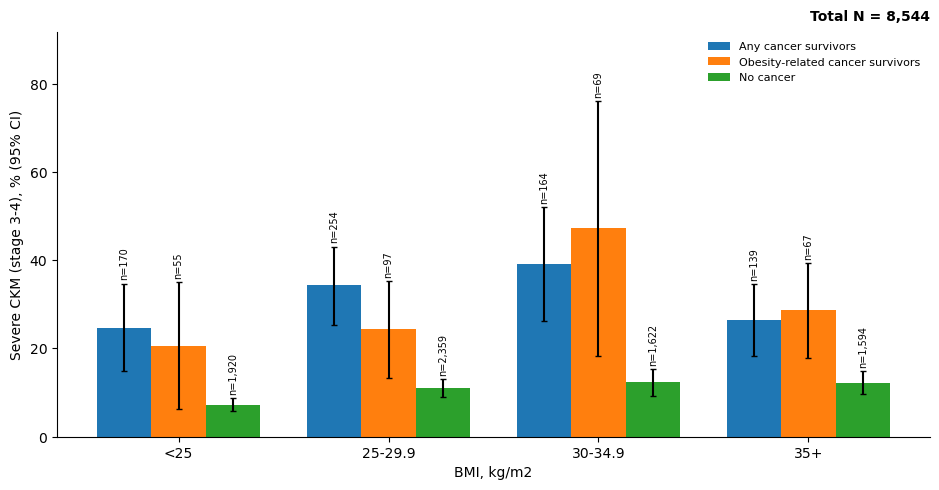

In [21]:
# severe CKM (stage 3-4) by BMI group: any-cancer survivors, obesity-related survivors, no cancer (design-based CIs)
bmi_cat = pd.cut(df["BMXBMI"], [0, 25, 30, 35, 100], right=False, labels=["<25", "25-29.9", "30-34.9", "35+"])
bmi_groups = [("Any cancer survivors", df["any_ca"].eq(1)), ("Obesity-related cancer survivors", df["iarc"]),
              ("No cancer", df["any_ca"].eq(0))]
rows = []
for gname, dom in bmi_groups:
    for cat in bmi_cat.cat.categories:
        mk = dom & bmi_cat.eq(cat)
        p, lo, hi, n = prevalence(df, mk)
        rows.append({"Group": gname, "BMI": cat, "n": n, "Severe CKM %": round(p, 1) if n >= 30 else np.nan,
                     "CI_lo": round(lo, 1) if n >= 30 else np.nan, "CI_hi": round(hi, 1) if n >= 30 else np.nan})
bmi_tbl = pd.DataFrame(rows)
print(bmi_tbl.to_string(index=False))
print("groups with n < 30 are not estimated")
bmi_tbl.to_csv(os.path.join(OUT_DIR, "severe_ckm_by_bmi.csv"), index=False)

fig, ax = plt.subplots(figsize=(9.5, 5))
bw = 0.26
for i, (gname, _) in enumerate(bmi_groups):
    s = bmi_tbl[bmi_tbl.Group == gname].reset_index(drop=True)
    xs = np.arange(len(s)) + (i - 1) * bw
    vals = s["Severe CKM %"].fillna(0)
    ax.bar(xs, vals, bw, label=gname, color=f"C{i}")
    for j, r in s.iterrows():
        if pd.isna(r["Severe CKM %"]):
            ax.text(xs[j], 1, f"n={int(r.n)}, not estimated", ha="center", va="bottom", fontsize=6.5, rotation=90)
        else:
            ax.errorbar(xs[j], r["Severe CKM %"], yerr=[[r["Severe CKM %"] - r.CI_lo], [r.CI_hi - r["Severe CKM %"]]],
                        color="black", capsize=2)
            ax.text(xs[j], r.CI_hi + 0.8, f"n={int(r.n):,}", ha="center", va="bottom", fontsize=7, rotation=90)
ax.set_xticks(range(4))
ax.set_xticklabels(bmi_cat.cat.categories)
ax.set_xlabel("BMI, kg/m2")
ax.set_ylabel("Severe CKM (stage 3-4), % (95% CI)")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.text(1, 1.02, f"Total N = {len(df):,}", transform=ax.transAxes, ha="right", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Figure3_severe_CKM_by_BMI.png"), dpi=300)
plt.show()


In [22]:
# metabolic-kidney (MK) axis, independent of CVD: the same Stage 1-3 logic with every CVD criterion left out.
# MK 3 = very-high-risk kidney disease or kidney failure; the PREVENT and coronary-alone Stage 3 routes are CVD criteria and drop out here.
df["MK"] = np.select([comp0["kdigo_vh"] | comp0["kidney_failure"], comp0["stage2"], comp0["stage1"]], [3, 2, 1], default=0)
df["cvd"] = (comp0["stage4"] | comp0["chd_alone"]).astype(int)       # clinical CVD or a coronary code
for k in range(4):
    df[f"mk{k}"] = (df["MK"] == k).astype(float)

rows = []
for gname, dom in [("Any cancer survivors", df["any_ca"].eq(1)), ("Obesity-related cancer survivors", df["iarc"]),
                   ("No cancer", df["any_ca"].eq(0))]:
    for lab, cv in [("CVD present", 1), ("No CVD", 0)]:
        sub = dom & df["cvd"].eq(cv)
        n = int(sub.sum())
        row = {"Group": gname, "CVD": lab, "n": n}
        for k in range(4):
            p, lo, hi, _ = prevalence(df, sub, f"mk{k}")
            row[f"MK {k} %"] = f"{p:.1f} ({lo:.1f}-{hi:.1f})" if n >= 30 else "not estimated"
        rows.append(row)
mk_tbl = pd.DataFrame(rows)
print("weighted MK distribution within CVD status (row %, 95% CI)")
print(mk_tbl.to_string(index=False))
print("dual burden (CVD present and MK 3), unweighted n:", int(((df["cvd"] == 1) & (df["MK"] == 3) & df["any_ca"].eq(1)).sum()),
      "in any-cancer survivors")
r = design_wald(df, df["cvd"].map({1: "cvd", 0: "none"}), df["any_ca"].eq(1), y="MK", levels=[[0], [1], [2], [3]])
print("survivors, MK stage by CVD status: F(%d, %d) = %.2f, p = %s" % (r["df1"], r["df2"], r["F"], p_fmt(r["p"])))
mk_tbl.to_csv(os.path.join(OUT_DIR, "mk_axis.csv"), index=False)


weighted MK distribution within CVD status (row %, 95% CI)
                           Group         CVD    n           MK 0 %           MK 1 %            MK 2 %         MK 3 %
            Any cancer survivors CVD present  184    0.5 (0.0-1.5)    4.4 (0.0-9.0)  87.0 (81.3-92.6) 8.1 (5.0-11.1)
            Any cancer survivors      No CVD  567   7.0 (3.5-10.5) 20.1 (15.5-24.7)  70.7 (66.1-75.2)  2.2 (0.7-3.8)
Obesity-related cancer survivors CVD present   67    0.0 (0.0-0.0)   5.6 (0.0-16.1) 89.0 (77.7-100.0) 5.4 (0.0-11.1)
Obesity-related cancer survivors      No CVD  233   6.5 (0.3-12.8)  15.3 (7.4-23.2)  76.0 (68.1-83.9)  2.1 (0.7-3.5)
                       No cancer CVD present  842    2.1 (0.6-3.6)   9.7 (6.8-12.5)  84.0 (81.3-86.7)  4.3 (3.2-5.4)
                       No cancer      No CVD 6791 12.8 (10.9-14.7) 32.3 (30.1-34.4)  54.5 (51.2-57.7)  0.5 (0.3-0.7)
dual burden (CVD present and MK 3), unweighted n: 22 in any-cancer survivors
survivors, MK stage by CVD status: F(3, 23) =

In [23]:
# Table 3: factors associated with advanced CKM among all cancer survivors (survey-weighted logistic regression, strata and PSU).
# Staging inputs (HbA1c, eGFR, UACR, BMI, lipids) are left out so the model is not circular. Read it as "factors associated with", not predictors.
def design_logit_full(data, mask, cols, y="adv"):
    sub = data[mask & data[y].notna()]
    X = sub[cols].astype(float)
    X.insert(0, "const", 1.0)
    wt = np.nan_to_num(sub[W].values)
    fit = sm.GLM(sub[y].astype(float), X, family=sm.families.Binomial(), freq_weights=wt).fit()
    mu = fit.predict(X).values
    U = X.values * ((sub[y].values - mu) * wt)[:, None]
    full = np.zeros((len(data), X.shape[1]))
    full[data.index.get_indexer(sub.index)] = U
    g = pd.DataFrame(full).assign(s=data[STR].values, p=data[PSU].values).groupby(["s", "p"]).sum()
    meat, dof = np.zeros((X.shape[1],) * 2), 0
    for s, gg in g.groupby(level=0):
        n = len(gg)
        dof += n - 1
        if n > 1:
            c = gg.values - gg.values.mean(0)
            meat += n / (n - 1) * c.T @ c
    bread = np.linalg.inv((X.values * (wt * mu * (1 - mu))[:, None]).T @ X.values)
    return dict(names=list(X.columns), b=fit.params.values, cov=bread @ meat @ bread, dof=dof, n=len(sub),
                events=int(sub[y].sum()))

sv = df["any_ca"].eq(1)
df["nonwhite"] = (df["RIDRETH3"].map(race_map) != "NH White").astype(float)
t3_cols = ["age10", "female", "nonwhite", "e_main"]
res = design_logit_full(df, sv, t3_cols)
q = stats.t.ppf(0.975, res["dof"])
labels = {"age10": "Age, per 10 years", "female": "Female vs male", "nonwhite": "Non-White vs NH White",
          "e_main": "Obesity-related vs other cancer"}
rows = []
for nm, b, v in zip(res["names"], res["b"], np.diag(res["cov"])):
    if nm == "const":
        continue
    se = np.sqrt(v)
    rows.append({"Variable": labels[nm], "OR": round(np.exp(b), 2), "CI_lo": round(np.exp(b - q * se), 2),
                 "CI_hi": round(np.exp(b + q * se), 2), "p": p_fmt(2 * (1 - stats.t.cdf(abs(b / se), res["dof"])))})
table3 = pd.DataFrame(rows)
print("N =", res["n"], "| advanced CKM events =", res["events"], "| survivors = any reported cancer except skin-only")
print(table3.to_string(index=False))
table3.to_csv(os.path.join(OUT_DIR, "table3.csv"), index=False)


N = 751 | advanced CKM events = 254 | survivors = any reported cancer except skin-only
                       Variable   OR  CI_lo  CI_hi      p
              Age, per 10 years 1.64   1.37   1.97 <0.001
                 Female vs male 0.75   0.49   1.14  0.164
          Non-White vs NH White 1.14   0.66   1.98  0.623
Obesity-related vs other cancer 0.88   0.48   1.59  0.653


In [24]:
# stage 3 routes (a person can qualify through more than one)
comp = pd.DataFrame(list(df.apply(ckm_components, axis=1)), index=df.index)
s3 = df["CKM_Stage"] == 3
print("stage 3 n =", int(s3.sum()))
for c in ["kdigo_vh", "kidney_failure", "prevent_high", "chd_alone"]:
    print(f"  {c}: {int((comp[c] & s3).sum())}")
only_prevent = comp["prevent_high"] & ~comp["kdigo_vh"] & ~comp["kidney_failure"] & ~comp["chd_alone"]
print("  PREVENT only:", int((only_prevent & s3).sum()))

stage 3 n = 460
  kdigo_vh: 103
  kidney_failure: 25
  prevent_high: 296
  chd_alone: 94
  PREVENT only: 268


In [25]:
# sensitivity: complete case on the main lab and BP inputs (mostly selects the fasting subsample)
key_vars = ["BMXBMI", "LBXGH", "LBXGLU", "eGFR", "UACR", "BPXOSY1", "BPXODI1", "LBXTC", "LBDLDL", "LBDHDD", "LBXTR"]
dc = df.dropna(subset=key_vars)
cc_overall = prevalence(df, pd.Series(df.index.isin(dc.index), index=df.index))
print("complete case: n=%d, advanced CKM %.1f%% (%.1f-%.1f)" % (len(dc), cc_overall[0], cc_overall[1], cc_overall[2]))

complete case: n=3434, advanced CKM 12.6% (10.7-14.6)


In [26]:
# sensitivity: multiple imputation (m=5, Rubin), imputing every input the staging uses
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer

imp_cols = ["BMXBMI", "BMXWAIST", "LBXGH", "LBXGLU", "eGFR", "UACR", "SBP_mean", "DBP_mean",
            "LBDHDD", "LBXTR", "LBXTC", "LBDLDL"]
aux = ["RIDAGEYR", "RIAGENDR"]
base = df[imp_cols + aux].copy()
base["UACR"] = np.log1p(base["UACR"])
lo_b, hi_b = base.min(), base.max()
m_imp = 5
mi_groups = {"All adults": allm, "Obesity-related cancer survivors": df["iarc"],
             "Adults without obesity-related cancer": ~df["iarc"]}
est = {g: [] for g in mi_groups}
var = {g: [] for g in mi_groups}

for i in range(m_imp):
    imp = IterativeImputer(sample_posterior=True, max_iter=15, random_state=i)
    arr = pd.DataFrame(imp.fit_transform(base), columns=base.columns, index=base.index).clip(lo_b, hi_b, axis=1)
    dm = df.copy()
    dm[imp_cols] = arr[imp_cols]
    dm["UACR"] = np.expm1(arr["UACR"])
    dm["adv"] = dm.apply(classify_ckm, axis=1).isin([3, 4]).astype(float)
    for g, dom in mi_groups.items():
        p, se, dof, n = prevalence_se(dm, dom)
        est[g].append(p)
        var[g].append(se ** 2)
    print("imputation", i + 1, "overall advanced = %.2f%%" % est["All adults"][-1])

rows = []
for g in mi_groups:
    Q = np.array(est[g])
    U, B = np.mean(var[g]), Q.var(ddof=1)
    T = U + (1 + 1 / m_imp) * B
    nu = (m_imp - 1) * (1 + U / ((1 + 1 / m_imp) * B)) ** 2 if B > 0 else 1e6
    t_c = stats.t.ppf(0.975, min(nu, 1e6))
    rows.append({"Group": g, "MI advanced %": round(Q.mean(), 1),
                 "CI_lo": round(Q.mean() - t_c * np.sqrt(T), 1), "CI_hi": round(Q.mean() + t_c * np.sqrt(T), 1)})
mi_res = pd.DataFrame(rows)
print(mi_res.to_string(index=False))
mi_res.to_csv(os.path.join(OUT_DIR, "mi_results.csv"), index=False)

imputation 1 overall advanced = 12.99%
imputation 2 overall advanced = 13.02%
imputation 3 overall advanced = 13.01%
imputation 4 overall advanced = 13.04%
imputation 5 overall advanced = 13.05%
                                Group  MI advanced %  CI_lo  CI_hi
                           All adults           13.0   11.6   14.4
     Obesity-related cancer survivors           29.9   20.6   39.3
Adults without obesity-related cancer           12.4   11.0   13.7


In [27]:
# sensitivity: PREVENT inputs capped to the published ranges
f_cap = os.path.join(OUT_DIR, "prevent_output_capped.csv")
f_cap_in = os.path.join(OUT_DIR, "prevent_input_capped.csv")
if os.path.exists(f_cap) and os.path.getmtime(f_cap) < os.path.getmtime(f_cap_in):
    print("skipped, prevent_output_capped.csv is older than its input, rerun the R script")
elif os.path.exists(f_cap):
    pc = pd.read_csv(f_cap)[["SEQN", "prevent10_capped"]]
    tmp = df.drop(columns=["prevent10_capped"], errors="ignore").merge(pc, on="SEQN", how="left")
    tmp.index = df.index
    tmp["prevent_high"] = (tmp["prevent10_capped"] >= 0.20).fillna(False)
    tmp["stage_cap"] = tmp.apply(classify_ckm, axis=1)
    df["adv_cap"] = (tmp["stage_cap"] >= 3).astype(float)
    df["s3_cap"] = (tmp["stage_cap"] == 3).astype(float)
    for lab, mk in [("All adults", allm), ("Obesity-related cancer survivors", df["iarc"])]:
        p, lo, hi, n = prevalence(df, mk, y="adv_cap")
        p0, lo0, hi0, _ = prevalence(df, mk, y="adv")
        print(f"{lab}: capped {p:.1f}% ({lo:.1f}-{hi:.1f}) vs primary {p0:.1f}% ({lo0:.1f}-{hi0:.1f})")
    print("stage 3 capped, weighted: %.1f%%" % prevalence(df, allm, y="s3_cap")[0])
else:
    print("skipped, run the R script on prevent_input_capped.csv first")

All adults: capped 13.6% (12.1-15.2) vs primary 13.0% (11.5-14.4)
Obesity-related cancer survivors: capped 33.4% (23.4-43.5) vs primary 29.4% (19.5-39.4)
stage 3 capped, weighted: 4.8%


In [28]:
# age pattern: age distribution and advanced CKM by age band
df["band"] = pd.cut(df["RIDAGEYR"], [19, 39, 59, 120], labels=["20-39", "40-59", "60+"])
G = ["Adults without obesity-related cancer", "Obesity-related cancer survivors"]
df["grp2"] = np.where(df["iarc"], G[1], G[0])
rows = []
for gn in G:
    for b in ["20-39", "40-59", "60+"]:
        dom = (df["grp2"] == gn) & (df["band"] == b)
        p, lo, hi, n = prevalence(df, dom)
        share = df.loc[dom, W].sum() / df.loc[df["grp2"] == gn, W].sum() * 100
        rows.append({"Group": gn, "Age": b, "n": n, "Share": round(share, 1),
                     "Adv": round(p, 1), "lo": round(lo, 1), "hi": round(hi, 1)})
age_tbl = pd.DataFrame(rows)
print(age_tbl.to_string(index=False))
age_tbl.to_csv(os.path.join(OUT_DIR, "age_pattern.csv"), index=False)

                                Group   Age    n  Share  Adv   lo   hi
Adults without obesity-related cancer 20-39 2585   37.2  1.5  0.9  2.0
Adults without obesity-related cancer 40-59 2741   34.7  7.6  5.9  9.2
Adults without obesity-related cancer   60+ 2918   28.0 32.7 30.6 34.8
     Obesity-related cancer survivors 20-39   10    3.7  8.6  0.0 26.6
     Obesity-related cancer survivors 40-59   67   19.3 29.1 12.0 46.2
     Obesity-related cancer survivors   60+  223   77.0 30.5 19.6 41.5


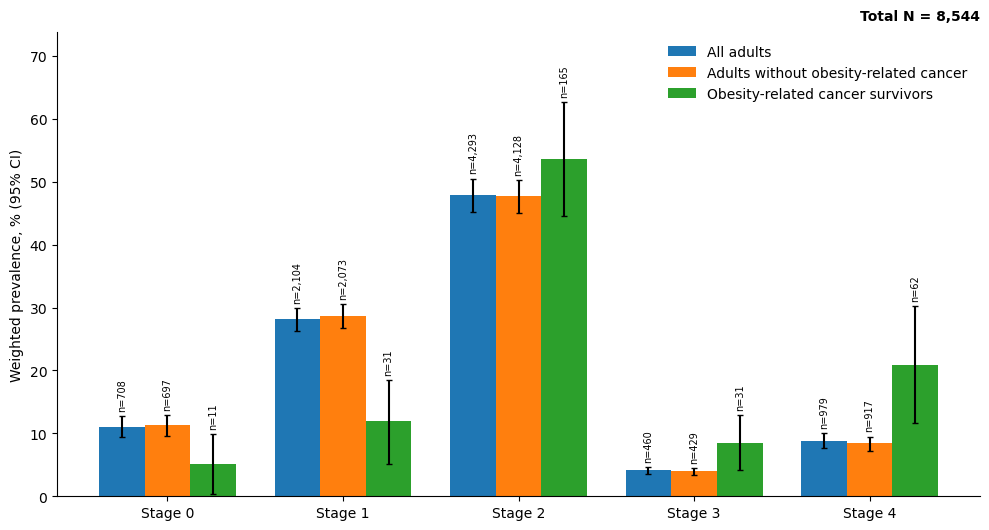

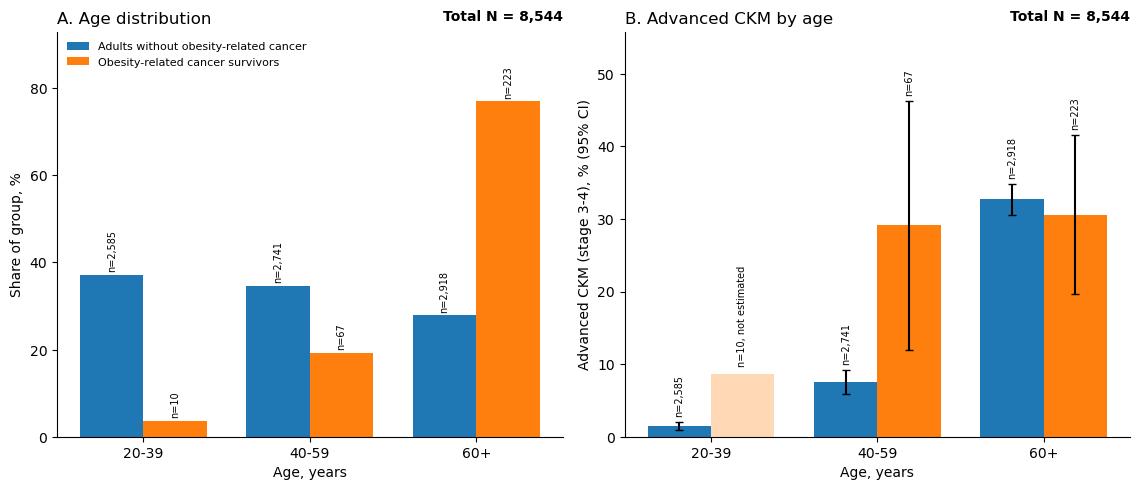

In [29]:
# figures 1-2 with n (unweighted people) over each bar
order = ["All adults", "Adults without obesity-related cancer", "Obesity-related cancer survivors"]
stages = ["Stage 0", "Stage 1", "Stage 2", "Stage 3", "Stage 4"]

# figure 1: stage distribution by group, n = people in that stage within the group
fig, ax = plt.subplots(figsize=(10, 5.4))
wd = 0.26
for i, g in enumerate(order):
    s = stage_ci[(stage_ci.Group == g) & stage_ci.Stage.isin(stages)].set_index("Stage").loc[stages]
    err = [s["Weighted %"] - s["CI_lo"], s["CI_hi"] - s["Weighted %"]]
    xs = np.arange(5) + (i - 1) * wd
    ax.bar(xs, s["Weighted %"], wd, yerr=err, capsize=2, label=g)
    for k, st in enumerate(stages):
        n_k = int((groups[g] & (df["CKM_Stage"] == k)).sum())
        ax.text(xs[k], s["CI_hi"].iloc[k] + 0.8, f"n={n_k:,}", ha="center", va="bottom", fontsize=7, rotation=90)
ax.set_xticks(range(5))
ax.set_xticklabels(stages)
ax.set_ylabel("Weighted prevalence, % (95% CI)")
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.text(1, 1.02, f"Total N = {int(groups['All adults'].sum()):,}", transform=ax.transAxes, ha="right", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Figure1_stage_distribution.png"), dpi=300)
plt.show()

# figure 2: age distribution and advanced CKM by age band, n = people in the band
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5))
x = np.arange(3)
bw = 0.38
for k, gn in enumerate(G):
    s = age_tbl[age_tbl.Group == gn].reset_index(drop=True)
    bars1 = a1.bar(x + (k - 0.5) * bw, s.Share, bw, label=gn)
    bars = a2.bar(x + (k - 0.5) * bw, s.Adv, bw, label=gn, color=f"C{k}")
    for j, r in s.iterrows():
        a1.text(x[j] + (k - 0.5) * bw, r.Share + 0.6, f"n={int(r.n):,}", ha="center", va="bottom", fontsize=7, rotation=90)
        if r.n < 30:
            bars[j].set_alpha(0.3)
            a2.text(x[j] + (k - 0.5) * bw, r.Adv + 1, f"n={int(r.n)}, not estimated", ha="center", va="bottom", fontsize=7, rotation=90)
        else:
            a2.errorbar(x[j] + (k - 0.5) * bw, r.Adv, yerr=[[r.Adv - r.lo], [r.hi - r.Adv]], color="black", capsize=3)
            a2.text(x[j] + (k - 0.5) * bw, r.hi + 0.8, f"n={int(r.n):,}", ha="center", va="bottom", fontsize=7, rotation=90)
for a, yl, ti in [(a1, "Share of group, %", "A. Age distribution"),
                  (a2, "Advanced CKM (stage 3-4), % (95% CI)", "B. Advanced CKM by age")]:
    a.set_xticks(x)
    a.set_xticklabels(["20-39", "40-59", "60+"])
    a.set_xlabel("Age, years")
    a.set_ylabel(yl)
    a.set_title(ti, loc="left")
    a.set_ylim(0, a.get_ylim()[1] * 1.15)
    a.spines[["top", "right"]].set_visible(False)
a1.legend(frameon=False, fontsize=8)
for a in (a1, a2):
    a.text(1, 1.02, f"Total N = {int(groups['All adults'].sum()):,}", transform=a.transAxes, ha="right", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "Figure2_age_pattern.png"), dpi=300)
plt.show()

In [30]:
# save every reported number to one file
final = {"stage_ci": stage_ci.to_dict("records"), "prevalence_groups": prev_groups.to_dict("records"),
         "odds_ratios": or_tbl.to_dict("records"), "adjusted_comparison": adj_tbl.to_dict("records"),
         "exposure_sensitivity": sens_def.to_dict("records"), "multiple_imputation": mi_res.to_dict("records"), "table3": table3.to_dict("records"),
         "age_pattern": age_tbl.to_dict("records"),
         "stage_tests_primary": t_all.to_dict("records"), "stage_tests_vs_no_cancer": t_none.to_dict("records"),
         "stage_tests_any_cancer": t_any.to_dict("records"), "stage_distribution_tests": stage_tests_tbl.to_dict("records"),
         "anthropometrics_obesity_related": anthro.to_dict("records"), "anthropometrics_any_cancer": anthro_any.to_dict("records"),
         "cancer_site_by_stage": site_stage.to_dict("records"), "severe_ckm_by_bmi": bmi_tbl.to_dict("records"),
         "mk_axis": mk_tbl.to_dict("records")}
json.dump(final, open(os.path.join(OUT_DIR, "manuscript_numbers.json"), "w"), indent=2, default=str)
print("saved manuscript_numbers.json")

saved manuscript_numbers.json
